In [ ]:
import pandas as pd

csv_text = '''site,month,usage,unit,bill_rm
KL Office,Jan-2025,12400,kWh,5208
KL Office,Feb-2025,11850,kWh,4977
KL Office,Mar-2025,12900,kwh,5418
KL Office,Apr-2025,13.1,MWh,5502
KL Office,May-2025,"13,250",kWh,5565
KL Office,Jun-2025,12700,kWh,5334
KL Office,Jul-2025,12950,kWh,5439
KL Office,Aug-2025,128500,kWh,5397
KL Office,Sep-2025,12600,kWh,5292
KL Office,Oct-2025,N/A,kWh,5460
KL Office,Nov-2025,12300,kWh,5166
KL Office,Dec-2025,12500,kWh,5250
KL Office,Dec-2025,12500,kWh,5250
Puchong Warehouse,Jan-2025,48200,kWh,21690
Puchong Warehouse,Feb-2025,46900,kWh,21105
puchong warehouse,2025-03,51000,kWh,22950
Puchong Warehouse,Apr-2025,49500,kWh,22275
Puchong Warehouse ,May-2025,50100,kWh,22545
Puchong Warehouse,Jul-2025,52300,kWh,23535
Puchong Warehose,Aug-2025,51800,kWh,23310
Puchong Warehouse,Sep-2025,49.9,MWh,22455
Puchong Warehouse,Oct-2025,50400,kW,22680
Puchong Warehouse,Nov-2025,-3200,kWh,-1440
Puchong Warehouse,Dec-2025,48800,kWh,21960
'''

with open("messy_bills.csv", "w") as f:
    f.write(csv_text)

# dtype=str keeps the data exactly as messy as it arrived
df = pd.read_csv("messy_bills.csv", dtype=str)
print(df.shape)
df.head(8)

(24, 5)


,site,month,usage,unit,bill_rm
0,KL Office,Jan-2025,12400,kWh,5208
1,KL Office,Feb-2025,11850,kWh,4977
2,KL Office,Mar-2025,12900,kwh,5418
3,KL Office,Apr-2025,13.1,MWh,5502
4,KL Office,May-2025,"13,250",kWh,5565
5,KL Office,Jun-2025,12700,kWh,5334
6,KL Office,Jul-2025,12950,kWh,5439
7,KL Office,Aug-2025,128500,kWh,5397


In [ ]:
df[df["site"].str.contains("KL")][["month", "usage", "unit"]].iloc[2:10]

,month,usage,unit
2,Mar-2025,12900,kwh
3,Apr-2025,13.1,MWh
4,May-2025,"13,250",kWh
5,Jun-2025,12700,kWh
6,Jul-2025,12950,kWh
7,Aug-2025,128500,kWh
8,Sep-2025,12600,kWh
9,Oct-2025,NaN,kWh


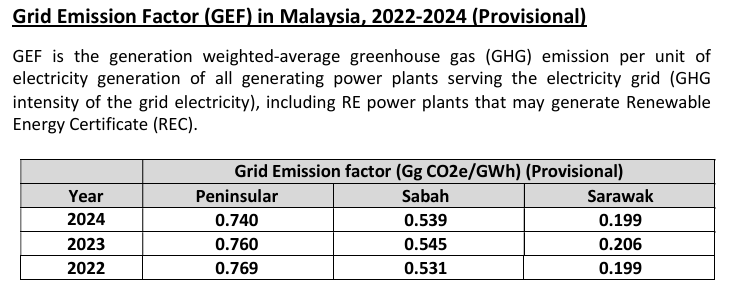

In [16]:
factors_csv = '''region,year,factor_kgco2e_per_kwh,status,source_name,source_url
Peninsular Malaysia,2024,0.740,provisional,Energy Commission (Suruhanjaya Tenaga) GEF in Malaysia 2022-2024,https://myenergystats.st.gov.my/documents/d/guest/grid-emission-factor-gef-in-malaysia-2022-2024-provisional-
Peninsular Malaysia,2023,0.760,provisional,Energy Commission (Suruhanjaya Tenaga) GEF in Malaysia 2022-2024,https://myenergystats.st.gov.my/documents/d/guest/grid-emission-factor-gef-in-malaysia-2022-2024-provisional-
Sabah,2024,0.539,provisional,Energy Commission (Suruhanjaya Tenaga) GEF in Malaysia 2022-2024,https://myenergystats.st.gov.my/documents/d/guest/grid-emission-factor-gef-in-malaysia-2022-2024-provisional-
Sarawak,2024,0.199,provisional,Sarawak Energy Berhad data via Energy Commission GEF 2022-2024,https://myenergystats.st.gov.my/documents/d/guest/grid-emission-factor-gef-in-malaysia-2022-2024-provisional-
'''

with open("emission_factors.csv", "w") as f:
    f.write(factors_csv)

factors = pd.read_csv("emission_factors.csv")
factors["factor_kgco2e_per_kwh"] = factors["factor_kgco2e_per_kwh"].astype(float)

def get_factor(region, year):
    """Return (factor, source_url, status). Fails loudly, never guesses."""
    match = factors[(factors["region"] == region) & (factors["year"] == year)]
    if match.empty:
        raise ValueError(f"No official factor for {region} {year}. Add one from the source, do not guess.")
    row = match.iloc[0]
    return row["factor_kgco2e_per_kwh"], row["source_url"], row["status"]

print(get_factor("Peninsular Malaysia", 2024))

(np.float64(0.74), 'https://myenergystats.st.gov.my/documents/d/guest/grid-emission-factor-gef-in-malaysia-2022-2024-provisional-', 'provisional')


**Data Cleaning**

In [5]:
from datetime import datetime
from difflib import get_close_matches

raw = pd.read_csv("messy_bills.csv", dtype=str)
raw["source_row"] = raw.index + 2   # CSV line number (header is line 1)

flags, changes = [], []

def add_flag(site, month, issue, action, src):
    flags.append({"site": site, "month": month, "issue": issue,
                  "suggested_action": action, "source_row": src})

def add_change(src, what):
    changes.append({"source_row": src, "change": what})

# 1. Exact duplicate raw rows: drop and log
dup_mask = raw.drop(columns="source_row").duplicated(keep="first")
for _, r in raw[dup_mask].iterrows():
    add_change(r["source_row"], f"Dropped exact duplicate of {r['site']} {r['month']}")
work = raw[~dup_mask].copy()

# 2. Site names: fuzzy match only against names seen 3+ times
work["site_key"] = work["site"].str.strip().str.lower().str.replace(r"\s+", " ", regex=True)
counts = work["site_key"].value_counts()
known = counts[counts >= 3].index.tolist()

def match_site(key):
    if key in known:
        return key
    m = get_close_matches(key, known, n=1, cutoff=0.85)
    return m[0] if m else key

work["site_key"] = work["site_key"].map(match_site)
display = (work.assign(s=work["site"].str.strip())
               .groupby("site_key")["s"]
               .agg(lambda x: x.value_counts().index[0]))
work["site_clean"] = work["site_key"].map(display)

# 3. Helpers
def parse_month(s):
    s = str(s).strip()
    for fmt in ("%b-%Y", "%Y-%m"):
        try:
            return datetime.strptime(s, fmt).strftime("%Y-%m")
        except ValueError:
            continue
    return None

def parse_number(s):
    if s is None or pd.isna(s):
        return None
    s = str(s).strip().replace(",", "")
    if s.lower() in ("", "n/a", "na", "nan", "-", "null"):
        return None
    try:
        return float(s)
    except ValueError:
        return None

UNIT_MAP = {"kwh": ("kWh", 1), "mwh": ("MWh", 1000)}

# 4. Row-by-row cleaning
rows = []
for _, r in work.iterrows():
    src, site = r["source_row"], r["site_clean"]
    month = parse_month(r["month"])
    usage, bill = parse_number(r["usage"]), parse_number(r["bill_rm"])
    unit_raw = str(r["unit"]).strip()
    ukey = unit_raw.lower()
    kwh = None

    if r["site"] != site:
        add_change(src, f"Site name '{r['site']}' -> '{site}'")
    if month is None:
        add_flag(site, r["month"], "Unparseable month", "Confirm period with client", src)

    if usage is None:
        add_flag(site, month, "Missing or non-numeric usage",
                 "Request actual reading from client. Do not estimate without approval.", src)
    elif ukey in UNIT_MAP:
        label, mult = UNIT_MAP[ukey]
        kwh = round(usage * mult, 6)
        if unit_raw != label:
            add_change(src, f"Unit '{unit_raw}' normalised to '{label}'")
        if mult != 1:
            add_change(src, f"Converted {usage} {label} to {kwh} kWh")
    elif ukey == "kw":
        add_flag(site, month, "Unit is kW (power, not energy)",
                 "Ask client for kWh consumption. Not converted.", src)
    else:
        add_flag(site, month, f"Unrecognised unit '{unit_raw}'",
                 "Confirm unit with client. Not converted.", src)

    rows.append({"site": site, "month": month, "kwh": kwh,
                 "bill_rm": bill, "source_row": src})

clean = pd.DataFrame(rows)
flags_df = pd.DataFrame(flags)
changes_df = pd.DataFrame(changes)

print("Clean rows:", len(clean))
print("Flags:", len(flags_df))
print("Changes:", len(changes_df))
clean

Clean rows: 23
Flags: 2
Changes: 7


,site,month,kwh,bill_rm,source_row
0,KL Office,2025-01,12400.0,5208.0,2
1,KL Office,2025-02,11850.0,4977.0,3
2,KL Office,2025-03,12900.0,5418.0,4
3,KL Office,2025-04,13100.0,5502.0,5
4,KL Office,2025-05,13250.0,5565.0,6
5,KL Office,2025-06,12700.0,5334.0,7
6,KL Office,2025-07,12950.0,5439.0,8
7,KL Office,2025-08,128500.0,5397.0,9
8,KL Office,2025-09,12600.0,5292.0,10
9,KL Office,2025-10,NaN,5460.0,11


In [6]:
flags_df

,site,month,issue,suggested_action,source_row
0,KL Office,2025-10,Missing or non-numeric usage,Request actual reading from client. Do not est...,11
1,Puchong Warehouse,2025-10,"Unit is kW (power, not energy)",Ask client for kWh consumption. Not converted.,23


In [7]:
changes_df

,source_row,change
0,14,Dropped exact duplicate of KL Office Dec-2025
1,4,Unit 'kwh' normalised to 'kWh'
2,5,Converted 13.1 MWh to 13100.0 kWh
3,17,Site name 'puchong warehouse' -> 'Puchong Ware...
4,19,Site name 'Puchong Warehouse ' -> 'Puchong War...
5,21,Site name 'Puchong Warehose' -> 'Puchong Wareh...
6,22,Converted 49.9 MWh to 49900.0 kWh


In [8]:
clean.groupby("site")["kwh"].count()

,kwh
site,
KL Office,11
Puchong Warehouse,10


Just to check data accuracy

In [9]:
checks = {
    "23 clean rows":            len(clean) == 23,
    "2 flags":                  len(flags_df) == 2,
    "7 changes":                len(changes_df) == 7,
    "only 2 distinct sites":    clean["site"].nunique() == 2,
    "KL May = 13250":           clean[(clean.site=="KL Office") & (clean.month=="2025-05")]["kwh"].iloc[0] == 13250,
    "KL Apr = 13100 (MWh)":     clean[(clean.site=="KL Office") & (clean.month=="2025-04")]["kwh"].iloc[0] == 13100,
    "Puchong Sep = 49900 (MWh)": clean[(clean.site=="Puchong Warehouse") & (clean.month=="2025-09")]["kwh"].iloc[0] == 49900,
    "kW row not converted":     pd.isna(clean[(clean.site=="Puchong Warehouse") & (clean.month=="2025-10")]["kwh"].iloc[0]),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - 23 clean rows
PASS - 2 flags
PASS - 7 changes
PASS - only 2 distinct sites
PASS - KL May = 13250
PASS - KL Apr = 13100 (MWh)
PASS - Puchong Sep = 49900 (MWh)
PASS - kW row not converted


In [10]:
EXPECTED_MONTHS = [f"2025-{m:02d}" for m in range(1, 13)]
SPIKE_MULT = 3.0      # flag usage above 3x the site median
TARIFF_TOL = 0.25     # flag implied tariff more than 25% from the site median

new_flags = []
implied_map = {}      # source_row -> implied kWh from bill (review only)

def flag(site, month, issue, action, src=None):
    new_flags.append({"site": site, "month": month, "issue": issue,
                      "suggested_action": action, "source_row": src})

for site, g in clean.groupby("site"):
    # Check 1: missing months (no row at all)
    for m in sorted(set(EXPECTED_MONTHS) - set(g["month"])):
        flag(site, m, "Missing month (no row in data)",
             "Request this month's bill from client", None)

    # Baselines use only positive, numeric usage
    pos = g[g["kwh"] > 0]
    median_kwh = pos["kwh"].median()
    median_tariff = (pos["bill_rm"] / pos["kwh"]).median()

    for _, r in g.iterrows():
        k, b, src = r["kwh"], r["bill_rm"], r["source_row"]

        # Implied kWh from the bill: for human review only, never inserted
        if pd.notna(b) and b > 0:
            implied_map[int(src)] = round(b / median_tariff)

        # Check 2: negative usage
        if pd.notna(k) and k < 0:
            flag(site, r["month"], "Negative usage",
                 "Confirm with client: credit, export or data error?", src)

        # Check 3: spike versus site median
        if pd.notna(k) and k > SPIKE_MULT * median_kwh:
            flag(site, r["month"],
                 f"Spike: {k:,.0f} kWh is over {SPIKE_MULT:.0f}x site median ({median_kwh:,.0f})",
                 "Verify against the original bill (possible extra digit)", src)

        # Check 4: implied tariff cross-check
        if pd.notna(k) and k > 0 and pd.notna(b) and b > 0:
            t = b / k
            if abs(t / median_tariff - 1) > TARIFF_TOL:
                flag(site, r["month"],
                     f"Implied tariff RM{t:.3f}/kWh vs site median RM{median_tariff:.3f}",
                     "Usage and bill disagree. Check for decimal or digit error", src)

# Combine without mutating the Step 3 flags (safe to re-run this cell)
all_flags = pd.concat([flags_df, pd.DataFrame(new_flags)], ignore_index=True)
all_flags["implied_kwh_from_bill"] = all_flags["source_row"].apply(
    lambda x: implied_map.get(int(x)) if pd.notna(x) else None)

# Mark rows that must be excluded from totals until a human approves them
flagged_src = set(all_flags["source_row"].dropna().astype(int))
clean["needs_review"] = clean["source_row"].isin(flagged_src)

print("Total flags:", len(all_flags))
print("Rows needing review:", int(clean["needs_review"].sum()))
print("Rows valid for calculation:", int((~clean["needs_review"] & clean["kwh"].notna()).sum()))
all_flags.sort_values(["site", "month"])

Total flags: 6
Rows needing review: 4
Rows valid for calculation: 19


,site,month,issue,suggested_action,source_row,implied_kwh_from_bill
2,KL Office,2025-08,"Spike: 128,500 kWh is over 3x site median (12,...",Verify against the original bill (possible ext...,9.0,12850.0
3,KL Office,2025-08,Implied tariff RM0.042/kWh vs site median RM0.420,Usage and bill disagree. Check for decimal or ...,9.0,12850.0
0,KL Office,2025-10,Missing or non-numeric usage,Request actual reading from client. Do not est...,11.0,13000.0
4,Puchong Warehouse,2025-06,Missing month (no row in data),Request this month's bill from client,NaN,NaN
1,Puchong Warehouse,2025-10,"Unit is kW (power, not energy)",Ask client for kWh consumption. Not converted.,23.0,50400.0
5,Puchong Warehouse,2025-11,Negative usage,"Confirm with client: credit, export or data er...",24.0,NaN


In [11]:
def has(site, month, text):
    m = all_flags[(all_flags.site == site) & (all_flags.month == month)]
    return m["issue"].str.contains(text, case=False).any()

checks = {
    "6 flags total":                     len(all_flags) == 6,
    "4 rows need review":                int(clean["needs_review"].sum()) == 4,
    "19 valid rows":                     int((~clean["needs_review"] & clean["kwh"].notna()).sum()) == 19,
    "KL Aug spike flagged":              has("KL Office", "2025-08", "Spike"),
    "KL Aug tariff flagged":             has("KL Office", "2025-08", "tariff"),
    "KL Oct missing usage flagged":      has("KL Office", "2025-10", "Missing or non-numeric"),
    "Puchong Jun missing month":         has("Puchong Warehouse", "2025-06", "Missing month"),
    "Puchong Oct kW flagged":            has("Puchong Warehouse", "2025-10", "kW"),
    "Puchong Nov negative flagged":      has("Puchong Warehouse", "2025-11", "Negative"),
    "KL Aug implied ~12,850":            all_flags[(all_flags.month=="2025-08") & (all_flags.site=="KL Office")]["implied_kwh_from_bill"].iloc[0] == 12850,
    "KL Oct implied ~13,000":            all_flags[(all_flags.month=="2025-10") & (all_flags.site=="KL Office")]["implied_kwh_from_bill"].iloc[0] == 13000,
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)

PASS - 6 flags total
PASS - 4 rows need review
PASS - 19 valid rows
PASS - KL Aug spike flagged
PASS - KL Aug tariff flagged
PASS - KL Oct missing usage flagged
PASS - Puchong Jun missing month
PASS - Puchong Oct kW flagged
PASS - Puchong Nov negative flagged
PASS - KL Aug implied ~12,850
PASS - KL Oct implied ~13,000


In [17]:
# Which grid each site is on. Add a site here before it can be calculated.
SITE_REGION = {
    "KL Office": "Peninsular Malaysia",
    "Puchong Warehouse": "Peninsular Malaysia",
}
DATA_YEAR = 2025      # year of the bills
FACTOR_YEAR = 2024    # latest published factor (2025 not yet available)

# Refuse to run if a site has no region mapping (never guess the grid)
unmapped = set(clean["site"]) - set(SITE_REGION)
if unmapped:
    raise ValueError(f"No grid region mapped for: {unmapped}")

calc = clean.copy()
calc["region"] = calc["site"].map(SITE_REGION)

# Only rows that passed every check and have a usage value
valid = calc[(~calc["needs_review"]) & calc["kwh"].notna()].copy()

# Look up the factor from the sourced file, never from memory
lookup = {r: get_factor(r, FACTOR_YEAR) for r in valid["region"].unique()}
valid["factor_kg_per_kwh"] = valid["region"].map(lambda r: lookup[r][0])
valid["tco2e"] = valid["kwh"] * valid["factor_kg_per_kwh"] / 1000   # kg to tonnes

# Summaries
by_site = (valid.groupby("site")
                .agg(rows=("kwh", "count"), kwh=("kwh", "sum"), tco2e=("tco2e", "sum"))
                .round(3))
total_kwh = valid["kwh"].sum()
total_t = round(valid["tco2e"].sum(), 3)
expected_site_months = len(SITE_REGION) * 12
coverage = len(valid) / expected_site_months

# Report, with the audit trail printed beside the result
print("SCOPE 2 (location-based), calendar year", DATA_YEAR)
print("-" * 60)
print(by_site)
print("-" * 60)
print(f"TOTAL (verified rows only): {total_kwh:,.0f} kWh = {total_t:,.3f} tCO2e")
print(f"Coverage: {len(valid)} of {expected_site_months} site-months ({coverage:.1%})")
print()
if FACTOR_YEAR != DATA_YEAR:
    print(f"WARNING: bills are {DATA_YEAR} but factor is {FACTOR_YEAR}.")
for region, (f, url, status) in lookup.items():
    if status != "final":
        print(f"WARNING: {region} factor is {status}, subject to Government endorsement.")
print("WARNING: total EXCLUDES flagged and missing months, so it understates real emissions.")

# What was excluded and why
excluded = all_flags[["site", "month", "issue", "suggested_action"]].sort_values(["site", "month"])
print("\nEXCLUDED PENDING REVIEW:")
excluded

SCOPE 2 (location-based), calendar year 2025
------------------------------------------------------------
                   rows       kwh    tco2e
site                                      
KL Office            10  126550.0   93.647
Puchong Warehouse     9  448500.0  331.890
------------------------------------------------------------
TOTAL (verified rows only): 575,050 kWh = 425.537 tCO2e
Coverage: 19 of 24 site-months (79.2%)


EXCLUDED PENDING REVIEW:


,site,month,issue,suggested_action
2,KL Office,2025-08,"Spike: 128,500 kWh is over 3x site median (12,...",Verify against the original bill (possible ext...
3,KL Office,2025-08,Implied tariff RM0.042/kWh vs site median RM0.420,Usage and bill disagree. Check for decimal or ...
0,KL Office,2025-10,Missing or non-numeric usage,Request actual reading from client. Do not est...
4,Puchong Warehouse,2025-06,Missing month (no row in data),Request this month's bill from client
1,Puchong Warehouse,2025-10,"Unit is kW (power, not energy)",Ask client for kWh consumption. Not converted.
5,Puchong Warehouse,2025-11,Negative usage,"Confirm with client: credit, export or data er..."


In [18]:
import json, re

site_rows = [{"site": s, "kwh": int(r["kwh"]), "tco2e": float(r["tco2e"]),
              "share_of_verified_total_pct": round(float(r["tco2e"]) / float(total_t) * 100, 1),
              "months_included": int(r["rows"])}
             for s, r in by_site.iterrows()]

issue_items = []
for (site, month), g in all_flags.groupby(["site", "month"]):
    issue_items.append({"site": site, "month": month,
                        "issues": g["issue"].tolist(),
                        "action": g["suggested_action"].iloc[0]})

f_val, f_url, f_status = lookup["Peninsular Malaysia"]
facts = {
    "reporting_year": DATA_YEAR,
    "method": "Scope 2, location-based",
    "verified_total_tco2e": float(total_t),
    "verified_total_kwh": int(total_kwh),
    "coverage": f"{len(valid)} of {expected_site_months} site-months",
    "emission_factor": {"value_kgco2e_per_kwh": float(f_val), "year": FACTOR_YEAR,
                        "status": f_status, "source": "Energy Commission of Malaysia"},
    "sites": site_rows,
    "items_needing_client_action": issue_items,
}

PROMPT = """You are a sustainability analyst writing to a client. Use ONLY the data in the JSON below.
Rules:
- Write about 150 words.
- Copy numbers exactly as written in the JSON. Do not round, convert, estimate or extrapolate.
- Do not state any number that is not in the JSON.
- State that the total covers verified data only, and say how many site-months it covers.
- Mention the emission factor year and that its status is provisional.
- End with one action item per site-month in items_needing_client_action.

DATA:
""" + json.dumps(facts, indent=2)
print(PROMPT)

You are a sustainability analyst writing to a client. Use ONLY the data in the JSON below.
Rules:
- Write about 150 words.
- Copy numbers exactly as written in the JSON. Do not round, convert, estimate or extrapolate.
- Do not state any number that is not in the JSON.
- State that the total covers verified data only, and say how many site-months it covers.
- Mention the emission factor year and that its status is provisional.
- End with one action item per site-month in items_needing_client_action.

DATA:
{
  "reporting_year": 2025,
  "method": "Scope 2, location-based",
  "verified_total_tco2e": 425.537,
  "verified_total_kwh": 575050,
  "coverage": "19 of 24 site-months",
  "emission_factor": {
    "value_kgco2e_per_kwh": 0.74,
    "year": 2024,
    "status": "provisional",
    "source": "Energy Commission of Malaysia"
  },
  "sites": [
    {
      "site": "KL Office",
      "kwh": 126550,
      "tco2e": 93.647,
      "share_of_verified_total_pct": 22.0,
      "months_included": 10
 

In [22]:
summary = """
{
  "reporting_year": 2025,
  "method": "Scope 2, location-based",
  "verified_total_tco2e": 425.537,
  "verified_total_kwh": 575050,
  "coverage": "19 of 24 site-months",
  "emission_factor": {
    "value_kgco2e_per_kwh": 0.74,
    "year": 2024,
    "status": "provisional",
    "source": "Energy Commission of Malaysia"
  },
  "sites": [
    {
      "site": "KL Office",
      "kwh": 126550,
      "tco2e": 93.647,
      "share_of_verified_total_pct": 22.0,
      "months_included": 10
    },
    {
      "site": "Puchong Warehouse",
      "kwh": 448500,
      "tco2e": 331.89,
      "share_of_verified_total_pct": 78.0,
      "months_included": 9
    }
  ],
  "items_needing_client_action": [
    {
      "site": "KL Office",
      "month": "2025-08",
      "issues": [
        "Spike: 128,500 kWh is over 3x site median (12,700)",
        "Implied tariff RM0.042/kWh vs site median RM0.420"
      ],
      "action": "Verify against the original bill (possible extra digit)"
    },
    {
      "site": "KL Office",
      "month": "2025-10",
      "issues": [
        "Missing or non-numeric usage"
      ],
      "action": "Request actual reading from client. Do not estimate without approval."
    },
    {
      "site": "Puchong Warehouse",
      "month": "2025-06",
      "issues": [
        "Missing month (no row in data)"
      ],
      "action": "Request this month's bill from client"
    },
    {
      "site": "Puchong Warehouse",
      "month": "2025-10",
      "issues": [
        "Unit is kW (power, not energy)"
      ],
      "action": "Ask client for kWh consumption. Not converted."
    },
    {
      "site": "Puchong Warehouse",
      "month": "2025-11",
      "issues": [
        "Negative usage"
      ],
      "action": "Confirm with client: credit, export or data error?"
    }
  ]
}
"""

def numbers_in(text):
    text = re.sub(r"(?m)^\s*\d+[.)]\s+", "", text)   # ignore list numbering like "1."
    return {float(x.replace(",", "")) for x in re.findall(r"\d[\d,]*(?:\.\d+)?", text)}

allowed = numbers_in(json.dumps(facts))
found = numbers_in(summary)
unsupported = sorted(found - allowed)

print("Numbers in summary:", sorted(found))
print("PASS - every number traces to the facts block" if not unsupported
      else f"FAIL - not in your data: {unsupported}")
print("Mentions provisional:", "provisional" in summary.lower())
print("Mentions coverage:", "19 of 24" in summary)
print("Word count:", len(summary.split()))

Numbers in summary: [0.042, 0.42, 0.74, 2.0, 3.0, 6.0, 8.0, 9.0, 10.0, 11.0, 19.0, 22.0, 24.0, 78.0, 93.647, 331.89, 425.537, 2024.0, 2025.0, 12700.0, 126550.0, 128500.0, 448500.0, 575050.0]
PASS - every number traces to the facts block
Mentions provisional: True
Mentions coverage: True
Word count: 191


In [23]:
def flag_hit(site, month, text):
    m = all_flags[(all_flags.site == site) & (all_flags.month == month)]
    return bool(m["issue"].str.contains(text, case=False).any())

def change_hit(src, text):
    m = changes_df[changes_df.source_row == src]
    return bool(m["change"].str.contains(text, case=False).any())

def kwh_of(src):    return clean.loc[clean.source_row == src, "kwh"].iloc[0]
def month_of(src):  return clean.loc[clean.source_row == src, "month"].iloc[0]
def excluded(src):  return bool(clean.loc[clean.source_row == src, "needs_review"].iloc[0])

KL, PW = "KL Office", "Puchong Warehouse"

planted = [
    (1,  "Unit case variant (kwh)",        lambda: change_hit(4, "normalised")),
    (2,  "MWh converted (KL Apr, Puch Sep)", lambda: change_hit(5, "Converted") and change_hit(22, "Converted")
                                                  and kwh_of(5) == 13100 and kwh_of(22) == 49900),
    (3,  "Thousands separator",            lambda: kwh_of(6) == 13250),
    (4,  "KL Aug 128,500 spike, excluded", lambda: flag_hit(KL, "2025-08", "Spike") and excluded(9)),
    (5,  "KL Oct missing usage, excluded", lambda: flag_hit(KL, "2025-10", "Missing or non-numeric") and excluded(11)),
    (6,  "Exact duplicate removed + logged", lambda: change_hit(14, "duplicate")),
    (7,  "Site name variants merged",      lambda: all(change_hit(s, "Site name") for s in (17, 19, 21))
                                                  and clean["site"].nunique() == 2),
    (8,  "Mixed date format parsed",       lambda: month_of(17) == "2025-03"),
    (9,  "Puchong Jun missing month",      lambda: flag_hit(PW, "2025-06", "Missing month")),
    (10, "kW flagged, not converted",      lambda: flag_hit(PW, "2025-10", "kW") and pd.isna(kwh_of(23)) and excluded(23)),
    (11, "Negative usage flagged",         lambda: flag_hit(PW, "2025-11", "Negative") and excluded(24)),
]

caught = 0
for n, label, test in planted:
    ok = test()
    caught += ok
    print("CAUGHT" if ok else "MISSED", f"- #{n} {label}")

expected_keys = {(KL, "2025-08"), (KL, "2025-10"), (PW, "2025-06"), (PW, "2025-10"), (PW, "2025-11")}
actual_keys = set(zip(all_flags["site"], all_flags["month"]))
false_alarms = actual_keys - expected_keys
leaked = {9, 11, 23, 24} & set(valid["source_row"])

print(f"\nScore: {caught}/11 planted errors caught")
print("False alarms:", false_alarms if false_alarms else "none")
print("Bad rows leaked into totals:", leaked if leaked else "none")

CAUGHT - #1 Unit case variant (kwh)
CAUGHT - #2 MWh converted (KL Apr, Puch Sep)
CAUGHT - #3 Thousands separator
CAUGHT - #4 KL Aug 128,500 spike, excluded
CAUGHT - #5 KL Oct missing usage, excluded
CAUGHT - #6 Exact duplicate removed + logged
CAUGHT - #7 Site name variants merged
CAUGHT - #8 Mixed date format parsed
CAUGHT - #9 Puchong Jun missing month
CAUGHT - #10 kW flagged, not converted
CAUGHT - #11 Negative usage flagged

Score: 11/11 planted errors caught
False alarms: none
Bad rows leaked into totals: none
